# Практичне заняття 2. Частина 2 — операції над матрицями через обробку зображень

## Завдання 1. Дзеркальне відображення та транспонування

Matplotlib is building the font cache; this may take a moment.


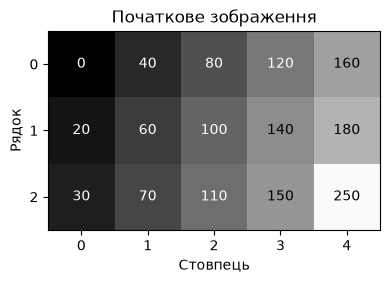

G | shape: (3, 5) | dtype: uint8 | size: 15 | nbytes: 15
  Значення 40 знаходиться в [[0, 1]]
  Значення 250 знаходиться в [[2, 4]]
  Набір значень збережено: True


In [1]:
import numpy as np
import matplotlib.pyplot as plt

G = np.array([
    [ 0, 40,  80, 120, 160],
    [20, 60, 100, 140, 180],
    [30, 70, 110, 150, 250]
], dtype=np.uint8)

def show_images(items):
    fig, axes = plt.subplots(1, len(items), figsize=(4 * len(items), 4))
    for ax, (data, title) in zip(np.atleast_1d(axes), items):
        if data.ndim == 2:
            ax.imshow(data, cmap="gray", vmin=0, vmax=255,
                      interpolation="nearest", origin="upper")
            for row in range(data.shape[0]):
                for col in range(data.shape[1]):
                    value = int(data[row, col])
                    ax.text(col, row, str(value), ha="center", va="center",
                            color="white" if value < 128 else "black")
        else:
            ax.imshow(data, interpolation="nearest", origin="upper")
        ax.set_xticks(range(data.shape[1]))
        ax.set_yticks(range(data.shape[0]))
        ax.set_xlabel("Стовпець")
        ax.set_ylabel("Рядок")
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

def describe(name, data):
    print(name, "| shape:", data.shape, "| dtype:", data.dtype,
          "| size:", data.size, "| nbytes:", data.nbytes)
    for value in [40, 250]:
        print("  Значення", value, "знаходиться в",
              np.argwhere(data == value).tolist())
    print("  Набір значень збережено:",
          np.array_equal(np.sort(data.ravel()), np.sort(G.ravel())))

show_images([(G, "Початкове зображення")])
describe("G", G)

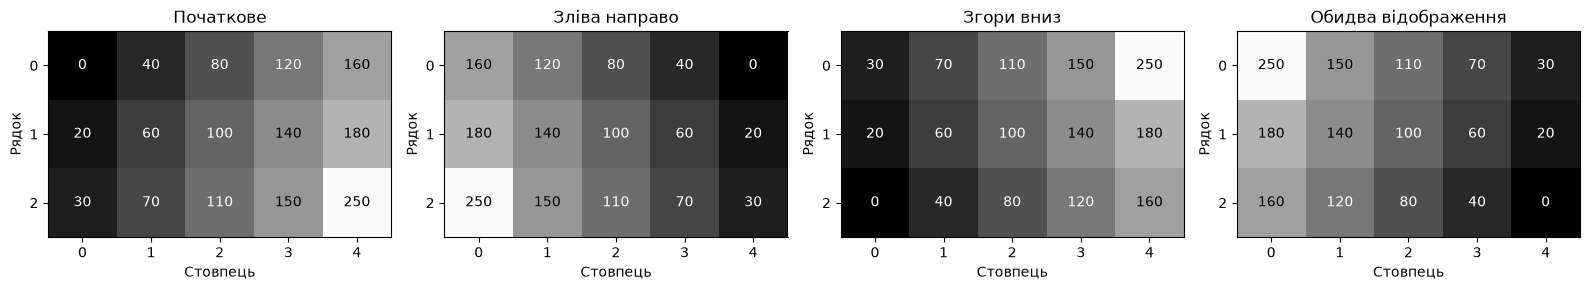

mirror_lr | shape: (3, 5) | dtype: uint8 | size: 15 | nbytes: 15
  Значення 40 знаходиться в [[0, 3]]
  Значення 250 знаходиться в [[2, 0]]
  Набір значень збережено: True
mirror_ud | shape: (3, 5) | dtype: uint8 | size: 15 | nbytes: 15
  Значення 40 знаходиться в [[2, 1]]
  Значення 250 знаходиться в [[0, 4]]
  Набір значень збережено: True
mirror_both | shape: (3, 5) | dtype: uint8 | size: 15 | nbytes: 15
  Значення 40 знаходиться в [[2, 3]]
  Значення 250 знаходиться в [[0, 0]]
  Набір значень збережено: True
Подвійне відображення зліва направо: True
Подвійне відображення згори вниз: True
Порядок двох відображень дає однаковий результат: True


In [2]:
mirror_lr = G[:, ::-1].copy()       # Змінюємо порядок стовпців
mirror_ud = G[::-1, :].copy()       # Змінюємо порядок рядків
mirror_both = G[::-1, ::-1].copy()  # Змінюємо обидва порядки

show_images([
    (G, "Початкове"),
    (mirror_lr, "Зліва направо"),
    (mirror_ud, "Згори вниз"),
    (mirror_both, "Обидва відображення")
])

for name, data in [
    ("mirror_lr", mirror_lr),
    ("mirror_ud", mirror_ud),
    ("mirror_both", mirror_both)
]:
    describe(name, data)

restored_lr = mirror_lr[:, ::-1].copy()
restored_ud = mirror_ud[::-1, :].copy()

lr_then_ud = mirror_lr[::-1, :].copy()
ud_then_lr = mirror_ud[:, ::-1].copy()

print("Подвійне відображення зліва направо:",
      np.array_equal(restored_lr, G))
print("Подвійне відображення згори вниз:",
      np.array_equal(restored_ud, G))
print("Порядок двох відображень дає однаковий результат:",
      np.array_equal(lr_then_ud, ud_then_lr))

### Питання до частини А

* **Який зріз змінює горизонтальне положення пікселів, а який — вертикальне? Поясніть через рядки й стовпці.**
  Зріз `G[:, ::-1]` змінює порядок стовпців (друга вісь), що призводить до дзеркального відображення зліва направо (горизонтальна зміна). Зріз `G[::-1, :]` змінює порядок рядків (перша вісь), що спричиняє відображення згори вниз (вертикальна зміна).
* **Чому подвійне відображення відновлює оригінал?**
  Застосування операції інверсування порядку двічі повертає елементи на їхні початкові місця ($[::-1][::-1] \equiv :$), оскільки перестановка елементів у зворотному порядку, виконана двічі, є тотожним перетворенням.
* **На який поворот схожий результат двох відображень? Обґрунтуйте через розташування двох контрольних пікселів.**
  Одночасне відображення за обома осями (`mirror_both`) еквівалентно **повороту зображення на 180°**. Наприклад, піксель `40` перемістився з `(0, 1)` у `(2, 3)`, а `250` — з `(2, 4)` у `(0, 0)`, що повністю відповідає симетричному розвороту навколо центра матриці.

## Б. Транспонування та поворот на 90°

### Таблиця Б
Для початкової матриці $G$ форма до транспонування — `(3, 5)`. Після транспонування та поворотів форма стає `(5, 3)`. Значення `40` спочатку в `(0, 1)`, а `250` — в `(2, 4)`.

| Перетворення | Прогноз координат 40 | Фактичні координати 40 | Прогноз координат 250 | Фактичні координати 250 | shape |
| --- | --- | --- | --- | --- | --- |
| Транспонування | (1, 0) | (1, 0) | (4, 2) | (4, 2) | (5, 3) |
| 90° за годинниковою стрілкою | (1, 4) | (1, 4) | (4, 0) | (4, 0) | (5, 3) |
| 90° проти годинникової стрілки | (3, 0) | (3, 0) | (0, 2) | (0, 2) | (5, 3) |

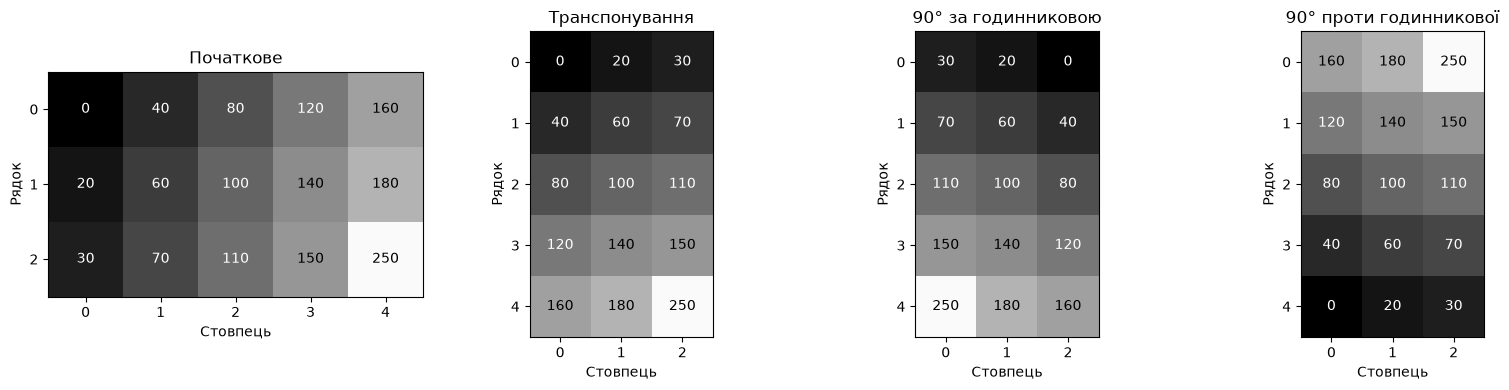

transposed | shape: (5, 3) | dtype: uint8 | size: 15 | nbytes: 15
  Значення 40 знаходиться в [[1, 0]]
  Значення 250 знаходиться в [[4, 2]]
  Набір значень збережено: True
rotated_cw | shape: (5, 3) | dtype: uint8 | size: 15 | nbytes: 15
  Значення 40 знаходиться в [[1, 2]]
  Значення 250 знаходиться в [[4, 0]]
  Набір значень збережено: True
rotated_ccw | shape: (5, 3) | dtype: uint8 | size: 15 | nbytes: 15
  Значення 40 знаходиться в [[3, 0]]
  Значення 250 знаходиться в [[0, 2]]
  Набір значень збережено: True
Подвійне транспонування відновило оригінал: True
Транспонування дорівнює повороту за годинниковою: False


In [3]:
transposed = G.T.copy()

rotated_cw = G.T[:, ::-1].copy()
rotated_ccw = G.T[::-1, :].copy()

show_images([
    (G, "Початкове"),
    (transposed, "Транспонування"),
    (rotated_cw, "90° за годинниковою"),
    (rotated_ccw, "90° проти годинникової")
])

for name, data in [
    ("transposed", transposed),
    ("rotated_cw", rotated_cw),
    ("rotated_ccw", rotated_ccw)
]:
    describe(name, data)

restored_transpose = transposed.T.copy()
print("Подвійне транспонування відновило оригінал:",
      np.array_equal(restored_transpose, G))
print("Транспонування дорівнює повороту за годинниковою:",
      np.array_equal(transposed, rotated_cw))

Початкова форма: (2, 3, 3)
Форма RGB.T: (3, 3, 2)
Форма просторового транспонування: (3, 2, 3)
Контрольний піксель до: [255   0   0]
Контрольний піксель після: [255   0   0]
RGB-вектор збережено: True


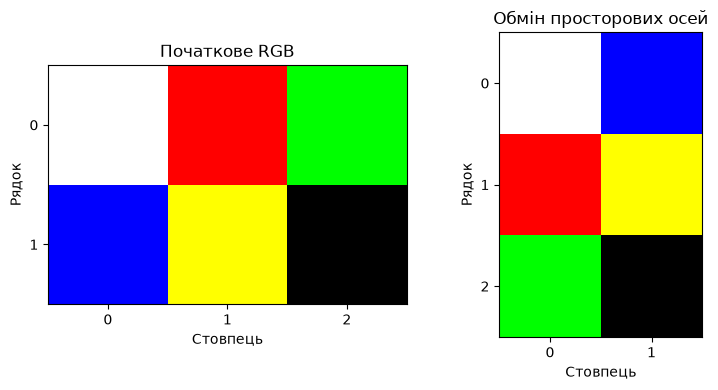

In [4]:
RGB = np.array([
    [[255, 255, 255], [255, 0, 0], [0, 255, 0]],
    [[  0,   0, 255], [255, 255, 0], [0, 0, 0]]
], dtype=np.uint8)

rgb_transposed = RGB.transpose(1, 0, 2).copy()

print("Початкова форма:", RGB.shape)
print("Форма RGB.T:", RGB.T.shape)
print("Форма просторового транспонування:", rgb_transposed.shape)
print("Контрольний піксель до:", RGB[0, 1])
print("Контрольний піксель після:", rgb_transposed[1, 0])
print("RGB-вектор збережено:",
      np.array_equal(RGB[0, 1], rgb_transposed[1, 0]))

show_images([
    (RGB, "Початкове RGB"),
    (rgb_transposed, "Обмін просторових осей")
])

### Питання до частини Б та Висновки

* **Чому транспонування й поворот мають однакову форму, але різне розташування пікселів?**
  Транспонування міняє місцями рядки та стовпці ($T[col, row] = G[row, col]$), що є відбиттям відносно головної діагоналі. Поворот на 90° вимагає не лише обміну осей, а й додаткового дзеркального відображення однієї з осей для збереження правильної орієнтації зображення.
* **Чому для прямокутного зображення міняються місцями висота й ширина, а кількість пікселів зберігається?**
  Висота відповідає кількості рядків, а ширина — кількості стовпців. При транспонуванні осі міняються місцями, тому розмірність `(height, width)` перетворюється на `(width, height)`. Загальна кількість пікселів — це добуток висоти на ширину ($H \cdot W = W \cdot H$), тому вона залишається незмінною.
* **Чому `RGB.T` не є потрібним просторовим транспонуванням? Поясніть значення осей у правильному результаті.**
  Метод `.T` транспонує *абсолютно всі* осі масиву в зворотному порядку (з `(2, 3, 3)` робить `(3, 3, 2)`). Це руйнує структуру пікселя, оскільки остання вісь каналів кольору (RGB) переміщується на перше місце. Для коректного транспонування зображення потрібно міняти місцями лише перші дві просторові осі за допомогою `RGB.transpose(1, 0, 2)`, залишаючи канали незмінними.
* **Чи змінилися `dtype`, `size`, `nbytes` одноканальних результатів? Чи достатньо рівності цих характеристик, щоб стверджувати, що два зображення однакові?**
  Ні, `dtype`, `size` та `nbytes` залишаються абсолютно однаковими для всіх перетворень, оскільки кількість елементів та тип даних не змінюються. Проте рівності цих характеристик **недостатньо**, щоб стверджувати, що зображення однакові, адже вони описують лише обсяг пам'яті, а не точне просторове розташування пікселів. Для перевірки ідентичності використовується `np.array_equal`.

### Загальний висновок
У ході лабораторної роботи було досліджено перестановку рядків і стовпців матриць зображень. З'ясовано, що дзеркальні відображення та транспонування змінюють виключно просторові координати пікселів, повністю зберігаючи їхній числовий набір, тип даних та загальну кількість. Доведено, що просте транспонування не еквівалентне повороту на 90° без додаткового дзеркального відображення, а при роботі з кольоровими RGB-масивами необхідно чітко розрізняти просторові осі та канали кольору.